In [16]:
%load_ext autoreload
%autoreload 2

import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
import mechFunctions as mf

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [15]:
P, L, l, D, Ga, Gs, Ta, Ts, Tp, J, phi, tau_s, tau_a = sp.symbols('P L l D Ga Gs Ta Ts Tp J phi tau_s tau_a')
consts = {L: 4*12, l: 2.5*12, D: 4, Ga: 3.7e6, Gs: 11e6, tau_s: 10e3}
x = [Ta, Ts, Tp, J, phi, tau_a, P]

eqs = [
    sp.Eq(J, (sp.pi/32)*D**4),
    sp.Eq(Tp, 2*l*P),
    sp.Eq(phi, Ta*L/(J*Ga)),
    sp.Eq(phi, Ts*L/(J*Gs)),
    sp.Eq(Ts, Tp - Ta),
    sp.Eq(tau_a, Ta*D/(2*J)),
    sp.Eq(tau_s, Ts*D/(2*J))
]

sol = sp.solve(eqs, x, dict=True)[0]
P = sp.factor((P).subs(sol))
display(sp.Eq(sp.Symbol('P'), P))
P_val = P.subs(consts)
print(float(P_val))


Eq(P, pi*D**3*tau_s*(Ga + Gs)/(32*Gs*l))

2798.8734550163617


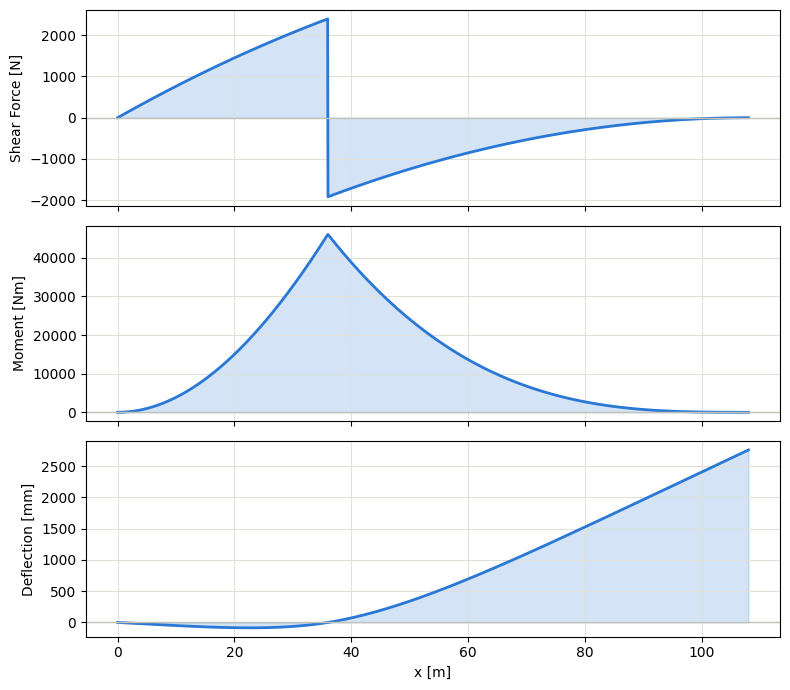

Mmax = 46045.5 lb-in at x = 36.02 in
Vmax = 2398.1 lb   at x = 35.96 in
25771.713579872907


In [27]:
x = sp.symbols('x')
L  = 9*12 
Lw = 3*12 
E = 10.6e6
c = 3/2

Ix = 2.68
wl = 80   
w = wl*(1 - x/L) 
P = []         
M = []  
fixed  = []              
pinned = [0.0,Lw]  

xs, V, Mb, v = mf.beam_diagrams(L, P, w, M, pinned, fixed, Ix, x, E, n=2001)
print(f"Mmax = {np.abs(Mb).max():.1f} lb-in at x = {xs[np.abs(Mb).argmax()]:.2f} in")
print(f"Vmax = {np.abs(V).max():.1f} lb   at x = {xs[np.abs(V).argmax()]:.2f} in")

Mmax = np.abs(Mb).max()

sigma = Mmax*c/Ix
print(sigma)


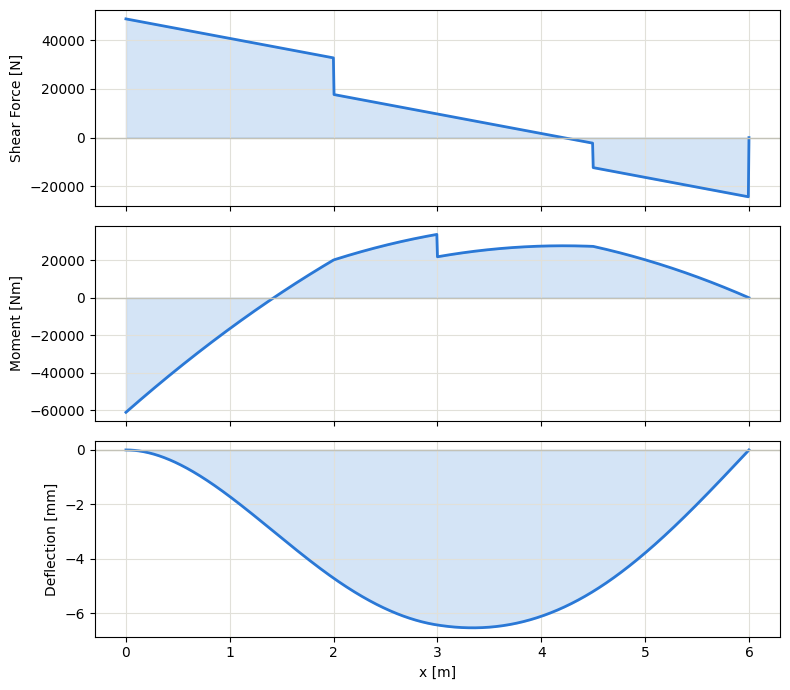

R_fixed  =   48.70 kN   with a wall moment of  -61.19 kN*m
R_pinned =   24.25 kN
Mmax =  33.85 kN*m at x = 2.99 m
Mmin = -61.19 kN*m at x = 0.00 m
max deflection = -6.53 mm at x = 3.34 m
sigma_max = 91.8 MPa


In [ ]:
# --- beam_diagrams() example -----------------------------------------------
# Propped cantilever: built in at the left end, resting on a pin at the right.
# Uniform cross-section and material along the whole span.

x = sp.symbols('x')                 # axial coordinate the w / E / I expressions are written in

L = 6.0                             # span [m]; x runs 0 -> L from the left end

# section and material, constant along the beam
E = 200e9                           # steel Young's modulus [Pa]
I, _ = mf.I_rectangles([0.0, 0.0, 0.10, 0.20])   # 100 x 200 mm rectangle [m^4]

# loads: forces are positive upward, couples positive counterclockwise
w = -8000                           # UDL of 8 kN/m pushing down [N/m] (may be any expression in x)
P = [(-15e3, 2.0),                  # 15 kN point load down at x = 2.0 m
     (-10e3, 4.5)]                  # 10 kN point load down at x = 4.5 m
C = [(12e3, 3.0)]                   # 12 kN*m counterclockwise couple at x = 3.0 m

# supports: fixed pins down deflection AND slope, pinned only deflection.
# One fixed + one pinned makes this beam statically indeterminate, which the
# function handles on its own (the extra equation comes from v = 0 at the pin).
fixed = [0.0]
pinned = [L]

xs, V, M, v = mf.beam_diagrams(L, P, w, C, pinned, fixed, I, x, E)

# each reaction is the jump in V at its support, so read them off the diagram
# (accurate to the grid spacing L/(n-1))
print(f"R_fixed  = {V[0]/1e3:7.2f} kN   with a wall moment of {M[0]/1e3:7.2f} kN*m")
print(f"R_pinned = {(V[-1] - V[-2])/1e3:7.2f} kN")
print(f"Mmax = {M.max()/1e3:6.2f} kN*m at x = {xs[M.argmax()]:.2f} m")
print(f"Mmin = {M.min()/1e3:6.2f} kN*m at x = {xs[M.argmin()]:.2f} m")

i = np.abs(v).argmax()
print(f"max deflection = {v[i]:.2f} mm at x = {xs[i]:.2f} m")

# peak bending stress from sigma = M*c/I, with c the half-depth of the section
print(f"sigma_max = {float(max(abs(M.max()), abs(M.min())) * 0.10 / I)/1e6:.1f} MPa")
